In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

train = pd.read_csv("../data/processed/train.csv", parse_dates=["StartDatetime"])
test = pd.read_csv("../data/processed/test.csv", parse_dates=["StartDatetime"])
sessions = pd.concat([train, test])

# One number per day: total energy demand of every session that started that day
series = sessions.set_index("StartDatetime").resample("D")["Demand"].sum()
series = series["2021-10-01":]        # drop 30 Sep 2021 (only 19 sessions, a partial day)

print(len(series), "days:", series.index[0].date(), "to", series.index[-1].date())    
print("Average daily demand:", round(series.mean()), "kWh")                            

365 days: 2021-10-01 to 2022-09-30
Average daily demand: 3478 kWh


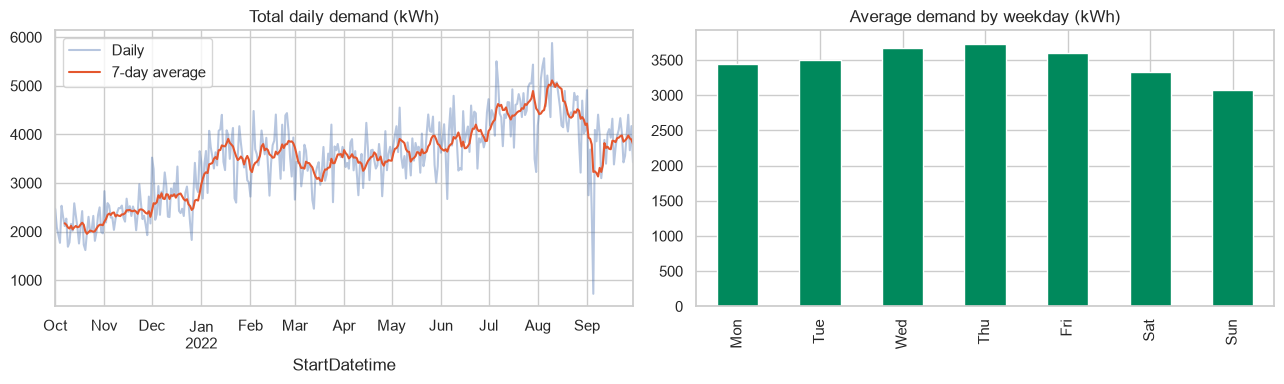

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

series.plot(ax=axes[0], alpha=0.4, label="Daily")
series.rolling(7).mean().plot(ax=axes[0], color="#E4572E", label="7-day average")
axes[0].set_title("Total daily demand (kWh)")
axes[0].legend()

weekday_avg = series.groupby(series.index.dayofweek).mean()
weekday_avg.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday_avg.plot(kind="bar", ax=axes[1], color="#00895C")
axes[1].set_title("Average demand by weekday (kWh)")

plt.tight_layout()
plt.savefig("../docs/figures/13_daily_demand_pattern.png", dpi=150, bbox_inches="tight")
plt.show()

In [3]:
def forecast_naive(history, horizon):
    """Tomorrow will look like today."""
    return np.full(horizon, history.iloc[-1])


def forecast_moving_average(history, horizon):
    """Every future day equals the average of the last 7 days."""
    return np.full(horizon, history.iloc[-7:].mean())


def forecast_seasonal_naive(history, horizon):
    """Each day repeats the same weekday of last week."""
    return np.resize(history.iloc[-7:].values, horizon)


def forecast_seasonal_average(history, horizon):
    """Each day uses the average of that weekday over the last 4 weeks."""
    weekday_pattern = history.iloc[-28:].values.reshape(4, 7).mean(axis=0)
    return np.resize(weekday_pattern, horizon)


def calendar_features(dates, start):
    """A day counter (for trend) plus weekday 0/1 columns."""
    features = pd.DataFrame({"day_number": (dates - start).days}, index=dates)
    for weekday in range(1, 7):
        features[f"weekday_{weekday}"] = (dates.dayofweek == weekday).astype(int)
    return features


def forecast_trend_weekday(history, horizon):
    """Linear regression on trend + weekday, fitted on the last 90 days."""
    recent = history.iloc[-90:]
    model = LinearRegression().fit(calendar_features(recent.index, history.index[0]), recent)
    future_dates = pd.date_range(history.index[-1] + pd.Timedelta(days=1), periods=horizon)
    return model.predict(calendar_features(future_dates, history.index[0]))


methods = {
    "Naive (last value)": forecast_naive,
    "Moving average (7 days)": forecast_moving_average,
    "Seasonal naive (last week)": forecast_seasonal_naive,
    "Seasonal average (last 4 weeks)": forecast_seasonal_average,
    "Trend + weekday regression": forecast_trend_weekday,
}

In [4]:
HORIZON = 7           # forecast one week ahead
N_ORIGINS = 12        # repeat the test 12 times, once per week
origins = [len(series) - HORIZON * k for k in range(N_ORIGINS, 0, -1)]


def backtest(method):
    """Pretend it is each 'origin' day, forecast the next 7 days, compare with what happened."""
    maes, mapes = [], []
    for origin in origins:
        history = series.iloc[:origin]                       # only data before the origin
        actual = series.iloc[origin:origin + HORIZON].values
        forecast = method(history, HORIZON)
        maes.append(np.abs(actual - forecast).mean())
        mapes.append((np.abs(actual - forecast) / actual).mean() * 100)
    return {"MAE_kWh": np.mean(maes), "MAPE_pct": np.mean(mapes)}


results = pd.DataFrame({name: backtest(method) for name, method in methods.items()}).T
results.sort_values("MAE_kWh").round(1)

,MAE_kWh,MAPE_pct
Moving average (7 days),488.1,16.6
Seasonal average (last 4 weeks),495.3,17.8
Trend + weekday regression,530.8,19.0
Seasonal naive (last week),562.7,19.4
Naive (last value),581.6,17.3


In [5]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing


def forecast_holt_winters(history, horizon):
    """Exponential smoothing with a damped trend and a weekly pattern."""
    model = ExponentialSmoothing(
        history, trend="add", damped_trend=True, seasonal="add", seasonal_periods=7
    ).fit()
    return model.forecast(horizon).values


try:
    results.loc["Holt-Winters"] = pd.Series(backtest(forecast_holt_winters))
    methods["Holt-Winters"] = forecast_holt_winters
except Exception as error:
    print("Holt-Winters skipped:", error)

results = results.sort_values("MAE_kWh")
results.round(1)

,MAE_kWh,MAPE_pct
Holt-Winters,413.9,15.0
Moving average (7 days),488.1,16.6
Seasonal average (last 4 weeks),495.3,17.8
Trend + weekday regression,530.8,19.0
Seasonal naive (last week),562.7,19.4
Naive (last value),581.6,17.3


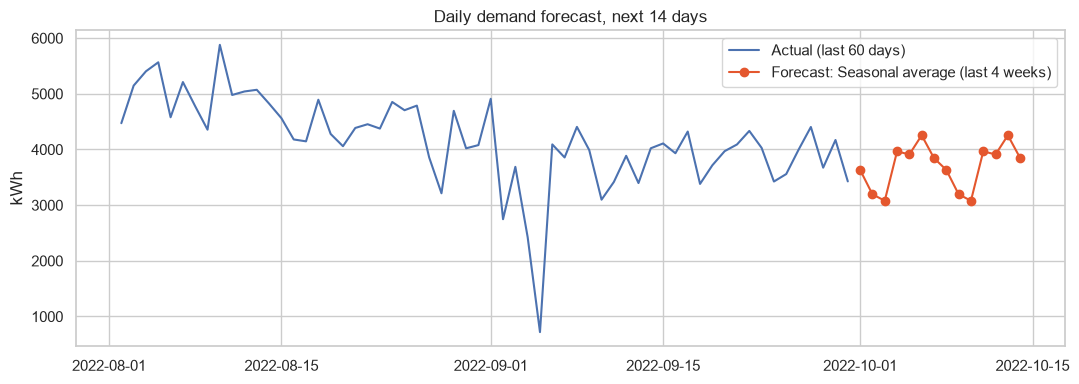

,Date,ForecastDemand_kWh
0,2022-10-01,3633.0
1,2022-10-02,3195.0
2,2022-10-03,3079.0
3,2022-10-04,3966.0
4,2022-10-05,3911.0
5,2022-10-06,4255.0
6,2022-10-07,3845.0
7,2022-10-08,3633.0
8,2022-10-09,3195.0
9,2022-10-10,3079.0


In [6]:
# The top methods differ by only a few kWh per day, which is noise.
# So we pick the one that also gives a useful weekday shape for planning.
chosen = "Seasonal average (last 4 weeks)"
FORECAST_DAYS = 14

future_dates = pd.date_range(series.index[-1] + pd.Timedelta(days=1), periods=FORECAST_DAYS)
future_values = methods[chosen](series, FORECAST_DAYS)
forecast = pd.DataFrame({"Date": future_dates, "ForecastDemand_kWh": future_values.round(0)})

plt.figure(figsize=(11, 4))
plt.plot(series.index[-60:], series.values[-60:], label="Actual (last 60 days)")
plt.plot(forecast["Date"], forecast["ForecastDemand_kWh"], color="#E4572E", marker="o", label=f"Forecast: {chosen}")
plt.title("Daily demand forecast, next 14 days")
plt.ylabel("kWh")
plt.legend()
plt.tight_layout()
plt.savefig("../docs/figures/14_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

forecast

In [7]:
forecast.to_csv("../models/forecast_next_14_days.csv", index=False)
results.round(2).to_csv("../models/forecast_backtest.csv")